# Fashion-MNIST Image Classification | TensorFlow & PyTorch

**From dense baselines to convolutional image classification**

This portfolio notebook explores Fashion-MNIST with TensorFlow/Keras: inspect the data, normalize pixel values, compare dense networks, and evaluate a convolutional neural network (CNN). PyTorch is reserved for a future comparison.


## Contents

1. Environment and dataset
2. Image exploration and preprocessing
3. Dense baseline and continued training
4. Regularized dense networks: ReLU and tanh
5. Convolutional neural network
6. Recorded results and next steps

[Project overview](../README.md) · [Detailed results](../results/README.md) · [Methodology](../docs/methodology.md)


<a href="https://colab.research.google.com/github/Akouaouchchaymae/fashion-mnist-classifier/blob/main/tensorflow/fashion_mnist_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Environment and Dataset

Import TensorFlow, NumPy, and Matplotlib. The saved environment reports TensorFlow 2.21.0.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot  as plt

print("Tensorflow version:", tf.__version__)

Tensorflow version: 2.22.0-rc0


### Load Fashion-MNIST

The Keras loader provides 60,000 training images and 10,000 test images, each a 28 × 28 grayscale array. Labels encode ten clothing and accessory categories.

In [2]:
fashion_minst = tf.keras.datasets.fashion_mnist
(x_train, y_train), (x_test, y_test) = fashion_minst.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [3]:
x_train.shape

(60000, 28, 28)

In [4]:
x_test.shape

(10000, 28, 28)

## 2. Image Exploration and Preprocessing

Inspect the first image array, its numeric label, and its grayscale rendering. Label 9 represents an ankle boot. Raw pixel intensities range from 0 to 255.

In [5]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
          0,   0,  13,  73,   0,   0,   1,   4,   0,   0,   0,   0,   1,
          1,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
          0,  36, 136, 127,  62,  54,   0,   0,   0,   1,   3,   4,   0,
          0,   3],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   6,
          0, 102, 204, 176, 134, 144, 123,  23,   0,   0,   0,   0,  12,
         10,   0],
       [  

In [6]:
y_train[0]

np.uint8(9)

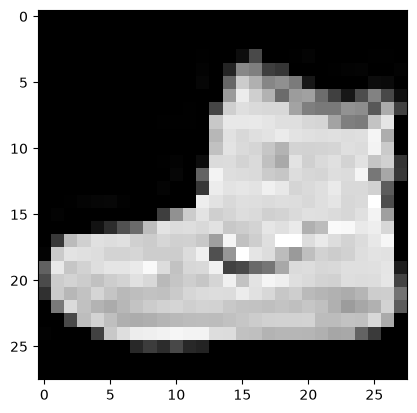

9


In [7]:
plt.imshow(x_train[0], cmap="gray")
plt.show()
print(y_train[0])

In [8]:
x_train.max()

np.uint8(255)

### Normalize Pixel Intensities

Divide both image sets by 255 to scale inputs to [0, 1]. Labels remain integer class identifiers for sparse categorical cross-entropy.

In [9]:
x_train_normalized = (x_train)/255
x_test_normalized = (x_test)/255

In [10]:
x_train_normalized.max()

np.float64(1.0)

## 3. Dense Baseline

Flatten each image into 784 features, apply a 128-unit ReLU hidden layer, and produce ten softmax probabilities. The saved summary reports 101,770 trainable parameters.

In [11]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

c:\Users\User\OneDrive\Bureau\Projekteee\fashion-mnist-classifier\.venv\Lib\site-packages\keras\src\layers\reshaping\flatten.py:36: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### Optimization and Initial Training

Use Adam with a learning rate of 0.001, sparse categorical cross-entropy, and accuracy. Training uses batches of 128 and a 20% validation split: 48,000 fitting examples and 12,000 validation examples.

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [14]:
history = model.fit(
    x_train_normalized, y_train,
    batch_size = 128,
    epochs=5,
    validation_split=0.2
)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8042 - loss: 0.5714 - val_accuracy: 0.8478 - val_loss: 0.4373
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8551 - loss: 0.4090 - val_accuracy: 0.8602 - val_loss: 0.3996
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8685 - loss: 0.3677 - val_accuracy: 0.8668 - val_loss: 0.3837
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8774 - loss: 0.3407 - val_accuracy: 0.8712 - val_loss: 0.3722
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8848 - loss: 0.3204 - val_accuracy: 0.8737 - val_loss: 0.3616


### Continue Training the Same Baseline

This 50-epoch call continues from the preceding five epochs; it does not initialize a new model. The following plot shows only this second training history.

In [15]:
history2 = model.fit(
    x_train_normalized, y_train,
    batch_size = 128,
    epochs=50,
    validation_split=0.2
)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8903 - loss: 0.3044 - val_accuracy: 0.8763 - val_loss: 0.3578
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8950 - loss: 0.2908 - val_accuracy: 0.8763 - val_loss: 0.3516
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8994 - loss: 0.2792 - val_accuracy: 0.8769 - val_loss: 0.3485
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9030 - loss: 0.2690 - val_accuracy: 0.8767 - val_loss: 0.3487
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9060 - loss: 0.2598 - val_accuracy: 0.8781 - val_loss: 0.3484
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9099 - loss: 0.2507 - val_accuracy: 0.8777 - val_loss: 0.3482
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9124 - loss: 0.2423 - val_accuracy: 0.8802 - val_loss: 0.3443
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9141 - loss: 0.2350 - val_accuracy: 0.

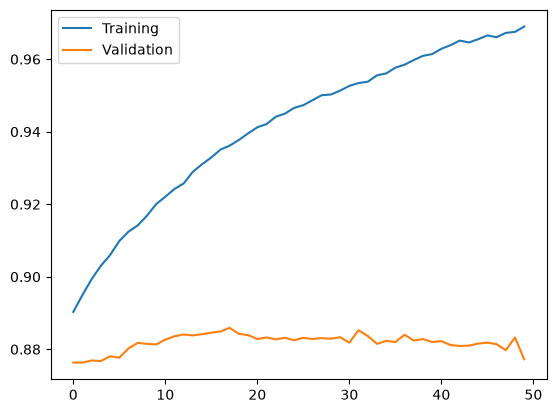

In [16]:
plt.plot(history2.history["accuracy"], label="Training")
plt.plot(history2.history["val_accuracy"], label="Validation")

plt.legend()
plt.show()

### Add Early Stopping to the Existing Baseline

Training continues again on the same weights. Early stopping monitors validation loss with patience 3 and restores the best weights from this call. This is a sequential exploration, rather than three independently initialized baseline trials. No baseline test evaluation is saved.

In [17]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history3 = model.fit(
    x_train_normalized,
    y_train,
    batch_size=128,
    epochs=50,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9696 - loss: 0.0903 - val_accuracy: 0.8775 - val_loss: 0.5200
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9699 - loss: 0.0895 - val_accuracy: 0.8745 - val_loss: 0.5301
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9702 - loss: 0.0890 - val_accuracy: 0.8716 - val_loss: 0.5465
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9712 - loss: 0.0867 - val_accuracy: 0.8711 - val_loss: 0.5584


## 4. Regularized Dense Networks

### Model 2 · ReLU with Dropout

Use hidden layers of 256 and 128 ReLU units, with 30% dropout after the first hidden layer. Training reuses the early-stopping callback configuration. The saved log contains 13 epochs, followed by test evaluation.

In [18]:
model2 = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [19]:
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [20]:
history_model2 = model2.fit(
    x_train_normalized,
    y_train,
    batch_size=128,
    epochs=50,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7903 - loss: 0.5864 - val_accuracy: 0.8498 - val_loss: 0.4269
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8497 - loss: 0.4166 - val_accuracy: 0.8609 - val_loss: 0.3878
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8606 - loss: 0.3815 - val_accuracy: 0.8684 - val_loss: 0.3727
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8690 - loss: 0.3561 - val_accuracy: 0.8752 - val_loss: 0.3521
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8756 - loss: 0.3384 - val_accuracy: 0.8720 - val_loss: 0.3590
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8791 - loss: 0.3277 - val_accuracy: 0.8735 - val_loss: 0.3502
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8831 - loss: 0.3151 - val_accuracy: 0.8828 - val_loss: 0.3329
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8872 - loss: 0.3046 - val_accuracy: 0.

### Evaluate the ReLU Dense Network

The saved test evaluation reports 87.93% accuracy and a loss of 0.347178 on 10,000 test images.

In [21]:
test_loss, test_accuracy = model2.evaluate(
    x_test_normalized,
    y_test
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8793 - loss: 0.3472
Test Accuracy: 0.8792999982833862
Test Loss: 0.3471778631210327


### Model 3 · Tanh with Dropout

Keep the 256/128 hidden-layer sizes and 30% dropout, replacing ReLU with tanh. Adam, loss, batch size, validation fraction, and early-stopping settings match the regularized ReLU experiment. The saved training log contains 16 epochs.

In [22]:

model3 = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="tanh"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="tanh"),
    tf.keras.layers.Dense(10, activation="softmax")
])


model3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
early_stop3 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


history_model3 = model3.fit(
    x_train_normalized,
    y_train,
    batch_size=128,
    epochs=50,
    validation_split=0.2,
    callbacks=[early_stop3]
)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8039 - loss: 0.5424 - val_accuracy: 0.8479 - val_loss: 0.4198
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8484 - loss: 0.4159 - val_accuracy: 0.8552 - val_loss: 0.4002
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8625 - loss: 0.3814 - val_accuracy: 0.8638 - val_loss: 0.3776
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8677 - loss: 0.3602 - val_accuracy: 0.8652 - val_loss: 0.3718
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8754 - loss: 0.3427 - val_accuracy: 0.8689 - val_loss: 0.3627
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8775 - loss: 0.3289 - val_accuracy: 0.8730 - val_loss: 0.3512
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8834 - loss: 0.3158 - val_accuracy: 0.8767 - val_loss: 0.3429
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8863 - loss: 0.3065 - val_accuracy: 0.

### Evaluate the Tanh Dense Network

The saved test evaluation reports 88.02% accuracy and a loss of 0.338194. The tanh variant has slightly higher recorded accuracy and lower loss than ReLU; a single run does not establish a reliable ranking.

In [24]:
test_loss3, test_accuracy3 = model3.evaluate(
    x_test_normalized,
    y_test
)

print("Model 3 Test Accuracy:", test_accuracy3)
print("Model 3 Test Loss:", test_loss3)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8802 - loss: 0.3382
Model 3 Test Accuracy: 0.8802000284194946
Model 3 Test Loss: 0.33819442987442017


## 5. Convolutional Neural Network

### Prepare Single-Channel Image Tensors

Reshape normalized inputs to (samples, 28, 28, 1), preserving spatial structure for convolution. The saved execution counts are retained, including their nonsequential values.

In [25]:
x_train_cnn = x_train_normalized.reshape(60000, 28, 28, 1)
x_test_cnn = x_test_normalized.reshape(10000, 28, 28, 1)
print(x_train_cnn.shape)
print(x_test_cnn.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


### Model 4 · Convolutional Architecture

Two 3 × 3 convolutional layers with 32 and 64 ReLU filters each feed a 2 × 2 max-pooling layer. Flattened features pass through a 128-unit ReLU layer, 30% dropout, and a ten-class softmax output.

In [26]:
model4 = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(10, activation="softmax")
])

model4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Train with Validation-Loss Early Stopping

Train for up to 50 epochs with batches of 128 and a 20% validation split. Patience is 3 and best weights are restored. The saved log contains 17 epochs; its lowest validation loss is 0.2378 at epoch 14.

In [27]:
early_stop4 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


history_model4 = model4.fit(
    x_train_cnn,
    y_train,
    batch_size=128,
    epochs=50,
    validation_split=0.2,
    callbacks=[early_stop4]
)

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.7652 - loss: 0.6459 - val_accuracy: 0.8444 - val_loss: 0.4237
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.8527 - loss: 0.4095 - val_accuracy: 0.8756 - val_loss: 0.3429
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.8727 - loss: 0.3523 - val_accuracy: 0.8855 - val_loss: 0.3150
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.8860 - loss: 0.3167 - val_accuracy: 0.8891 - val_loss: 0.3046
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.8932 - loss: 0.2941 - val_accuracy: 0.8981 - val_loss: 0.2809
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.9001 - loss: 0.2750 - val_accuracy: 0.9009 - val_loss: 0.2749
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.9058 - loss: 0.2585 - val_accuracy: 0.9016 - val_loss: 0.2666
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.9115 - loss: 0.2403 - 

### Evaluate the CNN

The saved test evaluation reports **90.88% accuracy** and **0.256100 loss**, the highest test accuracy among the three evaluated models in this notebook.

In [28]:
test_loss4, test_accuracy4 = model4.evaluate(
    x_test_cnn,
    y_test
)

print("Model 4 Test Accuracy:", test_accuracy4)
print("Model 4 Test Loss:", test_loss4)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9088 - loss: 0.2561
Model 4 Test Accuracy: 0.9088000059127808
Model 4 Test Loss: 0.2560997009277344


### Inspect Class Probabilities

Generate ten softmax probabilities for each of the 10,000 test images. The first prediction assigns the largest probability to class 9 (ankle boot). The original inline comments are retained as written.

In [29]:
# Vorhersagen mit unserem CNN
y_prob = model4.predict(x_test_cnn)

# Form der Vorhersagen überprüfen
print(y_prob.shape)

# Wahrscheinlichkeiten für das erste Bild anzeigen
print(y_prob[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
(10000, 10)
[2.4115566e-08 7.7231110e-11 6.8602776e-11 6.7387315e-12 6.3470133e-13
 6.9975372e-06 1.1571310e-11 9.3056524e-06 8.1792906e-11 9.9998367e-01]


## 6. Recorded Results and Next Steps

| Model | Test accuracy | Test loss |
| :--- | ---: | ---: |
| Dense baseline | Not recorded | Not recorded |
| ReLU dense + dropout | 87.93% | 0.347178 |
| Tanh dense + dropout | 88.02% | 0.338194 |
| CNN + dropout | **90.88%** | **0.256100** |

These values are transcribed from existing outputs, without rerunning any cells. The CNN exceeds the ReLU dense model by 2.95 percentage points in this saved experiment. Multiple test evaluations, no explicit random seed, and a single recorded run per evaluated architecture limit conclusions.

Future work: implement matched PyTorch models, document environment versions and seeds, and compare repeated runs using a consistent validation protocol. The PyTorch directory currently contains no implementation.

## Visualizing CNN Predictions

Inspect how the trained CNN (`model4`) classifies individual test images. Each panel shows the **predicted class**, **actual class**, and **prediction confidence**. Green titles indicate correct predictions; red titles highlight errors for closer inspection.

The class names below follow Fashion-MNIST's label order, from 0 to 9. The visualization selects images from `x_test_normalized`, adds the channel dimension expected by the CNN, and performs inference only. It does not compile, fit, or update the model.

**Prerequisites:** the current kernel must already contain the trained `model4`, normalized test images, and `y_test`, along with the existing NumPy and Matplotlib imports. Saved notebook outputs alone do not restore trained weights in a fresh kernel. No visualization code was executed during this documentation update.


In [30]:
# Fashion-MNIST class names, indexed by the original numeric labels.
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]


def visualize_cnn_predictions(indices=None, num_images=9, columns=3):
    """Display selected normalized test images with CNN predictions and labels."""
    if not isinstance(columns, (int, np.integer)) or columns < 1:
        raise ValueError("columns must be a positive integer.")

    if indices is None:
        if not isinstance(num_images, (int, np.integer)) or num_images < 1:
            raise ValueError("num_images must be a positive integer.")
        indices = np.arange(min(num_images, len(x_test_normalized)))
    else:
        indices = np.asarray(indices)
        if indices.ndim != 1 or indices.size == 0:
            raise ValueError("indices must be a nonempty, one-dimensional sequence.")
        if not np.issubdtype(indices.dtype, np.integer):
            raise ValueError("indices must contain integer test-image positions.")
        if np.any(indices < 0) or np.any(indices >= len(x_test_normalized)):
            raise ValueError("Each index must refer to an existing test image.")

    images = np.asarray(x_test_normalized)[indices]
    cnn_inputs = images.reshape(-1, 28, 28, 1)
    probabilities = np.asarray(model4.predict(cnn_inputs, verbose=0))
    predicted_labels = np.argmax(probabilities, axis=1)
    confidences = probabilities[np.arange(len(indices)), predicted_labels]
    actual_labels = np.asarray(y_test)[indices]

    columns = min(columns, len(indices))
    rows = (len(indices) + columns - 1) // columns
    fig, axes = plt.subplots(
        rows, columns, figsize=(4 * columns, 4 * rows), squeeze=False
    )
    for ax, image, index, predicted, actual, confidence in zip(
        axes.flat, images, indices, predicted_labels, actual_labels, confidences
    ):
        ax.imshow(image.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_title(
            f"Test image {index}\n"
            f"Predicted: {class_names[int(predicted)]}\n"
            f"Actual: {class_names[int(actual)]} | Confidence: {confidence:.1%}",
            fontsize=10,
            color="darkgreen" if predicted == actual else "firebrick",
        )
        ax.axis("off")

    for ax in list(axes.flat)[len(indices):]:
        ax.axis("off")
    fig.suptitle("Fashion-MNIST | CNN Predictions", fontsize=16)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


### View Multiple Test Predictions

The example below displays the first nine test images. Change `num_images` and `columns` to adjust the grid, or pass explicit positions such as `visualize_cnn_predictions(indices=[0, 12, 25, 100], columns=2)` to inspect selected examples. Explicit indices take precedence over `num_images`.

Confidence is the softmax probability assigned to the predicted class. It is a model score, not a calibrated guarantee of correctness; confident mistakes are useful examples to investigate.


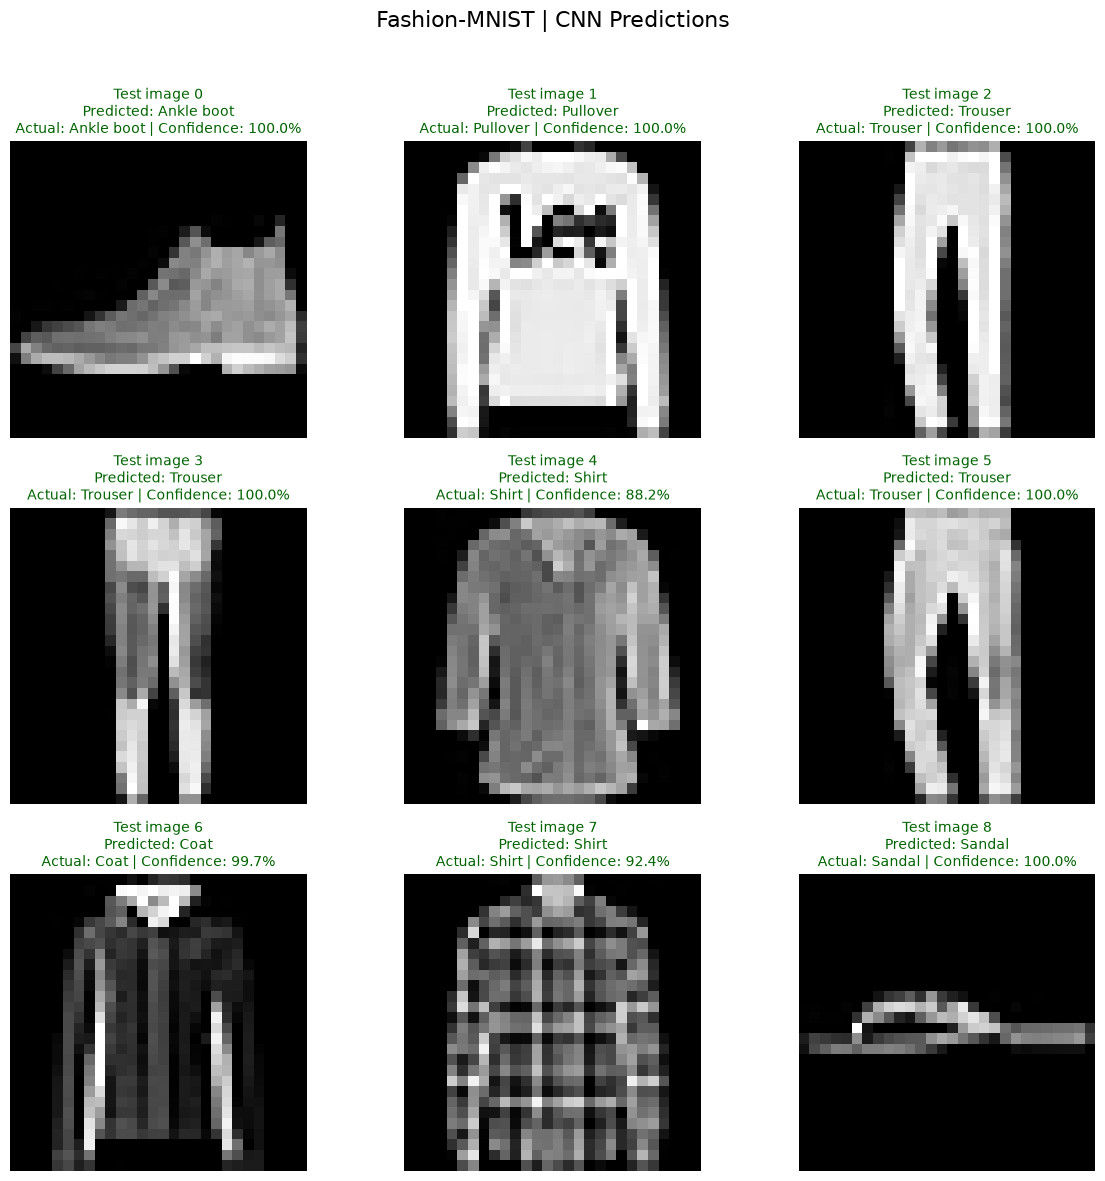

In [31]:
visualize_cnn_predictions(num_images=9, columns=3)
